# WordCount : Python simple vs pseudo-MapReduce vs Hadoop MapReduce

**Objectif** : compter le nombre d'occurrences de chaque mot d'un fichier avec trois approches (codes repris du rapport *ComptageMots.pdf*), puis les comparer selon trois axes :

| Axe | Question posée |
|---|---|
| **Structure** | Comment le traitement est-il découpé ? |
| **Outils** | Quelles technologies sont mobilisées ? |
| **Temps d'exécution** | Comment évolue la durée quand le volume augmente ? |

**Plan**
0. Données : les fichiers `data/mots_N.txt`, `data/mots_10N.txt`, `data/mots_100N.txt`, `data/mots_1000N.txt` et `data/mots_10000N.txt` (un mot par ligne)
1. Version 1 : Python simple
2. Version 2 : pseudo-MapReduce en Python (mapper → shuffle → reducer)
3. Version 3 : Hadoop MapReduce (HDFS + YARN, job `wordcount` officiel)
4. Comparaison et analyse

**Partie 2 — PySpark**

5. Le problème et présentation de PySpark
6. Mise en place de Spark
7. Le code expliqué (RDD puis DataFrame)
8. Tests
9. Mesures : temps, parallélisme, cache en mémoire
10. Comparaison avec la partie 1
11. Conclusion : ce qu'apporte PySpark

## 0. Données

On utilise cinq fichiers du dossier `data/`, contenant **un mot par ligne** :

| Fichier | Taille |
|---|---|
| `mots_N.txt` | N lignes |
| `mots_10N.txt` | 10·N lignes |
| `mots_100N.txt` | 100·N lignes |
| `mots_1000N.txt` | 1000·N lignes — créé ci-dessous en dupliquant `mots_N.txt` |
| `mots_10000N.txt` | 10000·N lignes — créé ci-dessous en dupliquant `mots_N.txt` |

Un temps isolé ne dit pas grand-chose : ce qui compte, c'est **comment il évolue avec le volume**.

### Création de `mots_1000N.txt` par duplication

On recopie 1 000 fois le contenu de `mots_N.txt` à la suite dans un nouveau fichier. Si le fichier existe déjà, on ne fait rien : on peut donc relancer la cellule sans le recréer.

In [21]:
from pathlib import Path

source = Path("data/mots_N.txt")
copie = Path("data/mots_1000N.txt")
NB_COPIES = 1000

if copie.exists():
    print(f"{copie} existe déjà : rien à faire")
else:
    contenu = source.read_text(encoding="utf-8")
    if not contenu.endswith("\n"):      # sinon le dernier mot d'une copie se colle au premier de la suivante
        contenu += "\n"
    with open(copie, "w", encoding="utf-8") as f:
        for _ in range(NB_COPIES):
            f.write(contenu)
    print(f"{copie} créé : {NB_COPIES} copies de {source}")

data/mots_1000N.txt existe déjà : rien à faire


### Création de `mots_10000N.txt` par duplication

Même principe, avec 10 000 copies de `mots_N.txt` (10 millions de lignes, environ 61 Mo). Si le fichier existe déjà, on ne fait rien.

In [22]:
source = Path("data/mots_N.txt")
copie = Path("data/mots_10000N.txt")
NB_COPIES = 10000

if copie.exists():
    print(f"{copie} existe déjà : rien à faire")
else:
    contenu = source.read_text(encoding="utf-8")
    if not contenu.endswith("\n"):      # sinon le dernier mot d'une copie se colle au premier de la suivante
        contenu += "\n"
    with open(copie, "w", encoding="utf-8") as f:
        for _ in range(NB_COPIES):
            f.write(contenu)
    print(f"{copie} créé : {NB_COPIES} copies de {source}")

data/mots_10000N.txt existe déjà : rien à faire


In [23]:
import os, sys, time, importlib
from pathlib import Path

DATA_DIR = Path("data")
CORPUS = {nom: DATA_DIR / f"mots_{nom}.txt" for nom in ["N", "10N", "100N", "1000N", "10000N"]}

LIGNES = {}
for nom, p in CORPUS.items():
    assert p.exists(), f"Fichier manquant : {p}"
    with open(p, encoding="utf-8") as f:
        LIGNES[nom] = sum(1 for _ in f)
    print(f"{p.name:15s} : {LIGNES[nom]:>10,d} lignes | {p.stat().st_size / 1e6:7.2f} Mo")

mots_N.txt      :      1,000 lignes |    0.01 Mo
mots_10N.txt    :     10,000 lignes |    0.06 Mo
mots_100N.txt   :    100,000 lignes |    0.61 Mo
mots_1000N.txt  :  1,000,000 lignes |    6.10 Mo
mots_10000N.txt : 10,000,000 lignes |   60.98 Mo


**Règle d'équité** : les trois versions découpent le texte de la même façon, avec `split()` (séparation sur les espaces et retours à la ligne, comme dans le rapport). Avec un mot par ligne, une ligne = un mot.

On mémorise les temps mesurés dans `RESULTATS` au fur et à mesure.

## 1. Version 1 — Python simple

**Principe** : on lit tout le fichier, on le découpe en mots, et on incrémente un compteur dans un **dictionnaire** (`mot -> nombre`).

- **Structure** : une seule boucle, un seul processus, une seule machine.
- **Mémoire** : le fichier entier (`f.read()`) + le dictionnaire final.
- **Limite** : tout dépend de la puissance d'**une** machine ; si le fichier fait 10 To, ça ne passe plus.

On enregistre le code tel quel dans `wordcount.py`, puis on l'exécute comme dans le rapport (`time python wordcount.py`).

In [24]:
%%writefile wordcount.py
import sys

def compter_occurrences(fichier):
    with open(fichier, 'r', encoding='utf-8') as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "data/mots_N.txt"
    resultats = compter_occurrences(fichier)
    for mot, nb in sorted(resultats.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

Overwriting wordcount.py


In [25]:
# Exécution du script comme dans le rapport (fichier de N lignes)
!time "{sys.executable}" wordcount.py data/mots_N.txt

chat : 120
chien : 100
fleur : 80
arbre : 80
maison : 70
soleil : 60
montagne : 60
livre : 50
ciel : 50
route : 40
mer : 40
lune : 40
eau : 35
oiseau : 30
voiture : 30
jardin : 30
pain : 20
table : 20
verre : 15
bouteille : 12
café : 10
porte : 8
"/Users/batistaureille/Desktop/Big Data/.venv/bin/python" wordcount.py   0.01s user 0.01s system 72% cpu 0.021 total


In [26]:
# Mesure du temps sur les 5 fichiers (fonction importée depuis wordcount.py)
import wordcount; importlib.reload(wordcount)

RESULTATS = []   # (version, corpus, temps en s)
res_v1 = {}
for nom, path in CORPUS.items():
    t0 = time.perf_counter()
    res_v1[nom] = wordcount.compter_occurrences(path)
    dt = time.perf_counter() - t0
    RESULTATS.append(("1. Python simple", nom, dt))
    print(f"{nom:6s} : {dt:8.4f} s | {len(res_v1[nom])} mots distincts")

print("\nbouteille :", {n: r.get("bouteille", 0) for n, r in res_v1.items()})

N      :   0.0004 s | 22 mots distincts
10N    :   0.0035 s | 22 mots distincts
100N   :   0.0260 s | 22 mots distincts
1000N  :   0.0864 s | 22 mots distincts
10000N :   0.6903 s | 22 mots distincts

bouteille : {'N': 12, '10N': 120, '100N': 1200, '1000N': 12000, '10000N': 120000}


## 2. Version 2 — pseudo-MapReduce en Python

On reproduit **à la main** les étapes de Hadoop, toujours sur une seule machine (code du rapport, *Listing 3*) :

1. **Map** (`mapper`) : chaque ligne est transformée en paires `(mot, 1)`.
2. **Shuffle** (`shuffle`) : on regroupe toutes les valeurs d'une même clé → `(mot, [1, 1, 1…])`.
3. **Reduce** (`reducer`) : on somme les valeurs de chaque clé → `(mot, total)`.

Intérêt pédagogique : voir le **modèle de programmation** sans l'infrastructure. Chaque appel à `mapper` est indépendant des autres → c'est ce qui le rend **parallélisable** sur un cluster.

In [27]:
%%writefile mapreduce_wordcount.py
import sys
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "data/mots_N.txt"
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    grouped = shuffle(mapped)
    reduced = reducer(grouped)

    for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {count}")

Overwriting mapreduce_wordcount.py


In [28]:
!time "{sys.executable}" mapreduce_wordcount.py data/mots_N.txt

chat : 120
chien : 100
fleur : 80
arbre : 80
maison : 70
soleil : 60
montagne : 60
livre : 50
ciel : 50
route : 40
mer : 40
lune : 40
eau : 35
oiseau : 30
voiture : 30
jardin : 30
pain : 20
table : 20
verre : 15
bouteille : 12
café : 10
porte : 8
"/Users/batistaureille/Desktop/Big Data/.venv/bin/python"  data/mots_N.txt  0.01s user 0.00s system 66% cpu 0.018 total


In [29]:
# Même enchaînement que le __main__ du script, en chronométrant chaque phase
import mapreduce_wordcount as mr; importlib.reload(mr)

res_v2, PHASES_V2 = {}, []
for nom, path in CORPUS.items():
    t = {}
    t0 = time.perf_counter()
    mapped = []
    with open(path, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mr.mapper(ligne))
    t["map"] = time.perf_counter() - t0
    t0 = time.perf_counter(); grouped = mr.shuffle(mapped);   t["shuffle"] = time.perf_counter() - t0
    t0 = time.perf_counter(); res_v2[nom] = mr.reducer(grouped); t["reduce"] = time.perf_counter() - t0
    total = sum(t.values())
    RESULTATS.append(("2. Pseudo-MapReduce", nom, total))
    PHASES_V2.append({"corpus": nom, **t, "paires intermédiaires": len(mapped)})
    print(f"{nom:6s} : {total:8.4f} s | " + " | ".join(f"{k} {v:.4f}s" for k, v in t.items())
          + f" | {len(mapped):,d} paires (mot,1) en mémoire")

assert all(res_v2[n] == res_v1[n] for n in CORPUS), "Résultats différents de la version 1 !"
print("\n✅ Résultats identiques à la version 1")

N      :   0.0419 s | map 0.0405s | shuffle 0.0015s | reduce 0.0000s | 1,000 paires (mot,1) en mémoire
10N    :   0.0035 s | map 0.0031s | shuffle 0.0004s | reduce 0.0000s | 10,000 paires (mot,1) en mémoire
100N   :   0.0208 s | map 0.0170s | shuffle 0.0037s | reduce 0.0002s | 100,000 paires (mot,1) en mémoire
1000N  :   0.1846 s | map 0.1523s | shuffle 0.0305s | reduce 0.0017s | 1,000,000 paires (mot,1) en mémoire
10000N :   2.0277 s | map 1.5594s | shuffle 0.4498s | reduce 0.0184s | 10,000,000 paires (mot,1) en mémoire

✅ Résultats identiques à la version 1


**À observer** : la version 2 est plus lente que la version 1 alors qu'elle fait le même calcul. La raison : elle **matérialise** toutes les paires intermédiaires `(mot, 1)` en mémoire, puis les regroupe. C'est le **coût du modèle MapReduce** : il est rentable seulement quand on peut répartir les mappers et reducers sur plusieurs machines.

## 3. Version 3 — Hadoop MapReduce (distribué)

On installe un vrai Hadoop sur le Mac en mode **pseudo-distribué** : tous les services tournent sur la même machine, mais ils communiquent exactement comme sur un cluster.

| Service | Rôle |
|---|---|
| **NameNode** (HDFS) | Annuaire : sait quel bloc de quel fichier est sur quelle machine |
| **DataNode** (HDFS) | Stocke physiquement les blocs |
| **ResourceManager** (YARN) | Répartit les ressources (CPU, RAM) entre les jobs |
| **NodeManager** (YARN) | Lance les tâches Map et Reduce dans des conteneurs |

Le job exécuté est le `wordcount` fourni avec Hadoop (écrit en Java), comme dans le pdf.

### 3.1 Installation de Java et Hadoop

Config Mac donnée par Claude, la cellule suivante fait l'équivalent automatiquement : Java 11 (Hadoop ne supporte pas les Java récents) et Hadoop 3.4.1 sont téléchargés dans `~/hadoop_tp`.

In [30]:
# Java 11 (Hadoop ne supporte pas les Java récents) et Hadoop, installés dans ~/hadoop_tp.
# Dossier sans espace volontairement : les scripts Hadoop supportent mal les chemins avec espaces
# (or ce projet est dans « Big Data »).
import subprocess, shutil, platform

TP_DIR = Path.home() / "hadoop_tp"
TP_DIR.mkdir(exist_ok=True)
assert " " not in str(TP_DIR), f"Le chemin {TP_DIR} contient un espace : choisir un autre TP_DIR"

HADOOP_VERSION = "3.4.1"
HADOOP_HOME = TP_DIR / "hadoop"
ARCH = "aarch64" if platform.machine() == "arm64" else "x64"

def telecharger(url, dest):
    print(f"Téléchargement de {url} ...")
    subprocess.run(["curl", "-fL", "--retry", "3", "-sS", "-o", str(dest), url], check=True)

# --- Java 11 (Eclipse Temurin) ---
if not list(TP_DIR.glob("jdk-11*")):
    tgz = TP_DIR / "jdk11.tar.gz"
    telecharger(f"https://api.adoptium.net/v3/binary/latest/11/ga/mac/{ARCH}/jdk/hotspot/normal/eclipse", tgz)
    subprocess.run(["tar", "-xzf", str(tgz), "-C", str(TP_DIR)], check=True)
    tgz.unlink()
JAVA_HOME = sorted(TP_DIR.glob("jdk-11*"))[-1] / "Contents" / "Home"

# --- Hadoop (version "lean" : sans le SDK AWS, plus légère) ---
if not HADOOP_HOME.exists():
    tgz = TP_DIR / "hadoop.tar.gz"
    nom = f"hadoop-{HADOOP_VERSION}-lean.tar.gz"
    try:
        telecharger(f"https://dlcdn.apache.org/hadoop/common/hadoop-{HADOOP_VERSION}/{nom}", tgz)
    except subprocess.CalledProcessError:
        telecharger(f"https://archive.apache.org/dist/hadoop/common/hadoop-{HADOOP_VERSION}/{nom}", tgz)
    subprocess.run(["tar", "-xzf", str(tgz), "-C", str(TP_DIR)], check=True)
    (TP_DIR / f"hadoop-{HADOOP_VERSION}").rename(HADOOP_HOME)
    tgz.unlink()

print(subprocess.run([f"{JAVA_HOME}/bin/java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])
print(subprocess.run([f"{HADOOP_HOME}/bin/hadoop", "version"], capture_output=True, text=True,
                     env={**os.environ, "JAVA_HOME": str(JAVA_HOME)}).stdout.splitlines()[0])

openjdk version "11.0.32.1" 2026-08-18
Hadoop 3.4.1


### 3.2 Configuration (mode pseudo-distribué)

Variables d'environnement + 4 fichiers XML :
- `core-site.xml` : adresse du système de fichiers (`hdfs://localhost:8020`)
- `hdfs-site.xml` : réplication = 1 (une seule machine, donc une seule copie possible)
- `mapred-site.xml` : les jobs MapReduce s'exécutent sur **YARN**
- `yarn-site.xml` : active le service de *shuffle* et assouplit des contrôles inutiles en local

In [31]:
import glob

os.environ.update({
    "JAVA_HOME": str(JAVA_HOME),
    "HADOOP_HOME": str(HADOOP_HOME),
    "HADOOP_CONF_DIR": f"{HADOOP_HOME}/etc/hadoop",
    "HADOOP_PID_DIR": f"{TP_DIR}/pids",
})
os.environ["PATH"] = f"{JAVA_HOME}/bin:{HADOOP_HOME}/bin:{HADOOP_HOME}/sbin:" + os.environ["PATH"]

def xml(props):
    body = "".join(f"  <property><name>{k}</name><value>{v}</value></property>\n" for k, v in props.items())
    return f"<?xml version=\"1.0\"?>\n<configuration>\n{body}</configuration>\n"

conf = Path(os.environ["HADOOP_CONF_DIR"])
(conf / "core-site.xml").write_text(xml({
    # Port 8020 (défaut Hadoop 3) : le 9000 est souvent pris par les noyaux Jupyter de VS Code
    "fs.defaultFS": "hdfs://localhost:8020",
    "hadoop.tmp.dir": f"{TP_DIR}/tmp",
}))
(conf / "hdfs-site.xml").write_text(xml({
    "dfs.replication": 1,
    "dfs.namenode.name.dir": f"file://{TP_DIR}/hdfs/namenode",
    "dfs.datanode.data.dir": f"file://{TP_DIR}/hdfs/datanode",
}))
mr_env = f"HADOOP_MAPRED_HOME={HADOOP_HOME}"
(conf / "mapred-site.xml").write_text(xml({
    "mapreduce.framework.name": "yarn",
    "yarn.app.mapreduce.am.env": mr_env,
    "mapreduce.map.env": mr_env,
    "mapreduce.reduce.env": mr_env,
}))
(conf / "yarn-site.xml").write_text(xml({
    "yarn.resourcemanager.hostname": "localhost",
    "yarn.nodemanager.aux-services": "mapreduce_shuffle",
    "yarn.nodemanager.vmem-check-enabled": "false",
    "yarn.nodemanager.disk-health-checker.max-disk-utilization-per-disk-percentage": 99,
}))
# Les démons lisent JAVA_HOME dans hadoop-env.sh
(conf / "hadoop-env.sh").write_text(
    (HADOOP_HOME / "etc/hadoop/hadoop-env.sh").read_text().split("\n# --- TP ---")[0]
    + f"\n# --- TP ---\nexport JAVA_HOME={JAVA_HOME}\n")

def sh(cmd, check=True, cwd=None):
    "Exécute une commande shell ; affiche l'erreur si elle échoue."
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, cwd=cwd)
    if check and r.returncode != 0:
        print(r.stdout[-2000:], r.stderr[-4000:])
        raise RuntimeError(f"Échec : {cmd}")
    return r

print("Configuration écrite dans", conf)

Configuration écrite dans /Users/batistaureille/hadoop_tp/hadoop/etc/hadoop


### 3.3 Démarrage de HDFS et YARN

Sur Mac, `start-dfs.sh` / `start-yarn.sh` passent par SSH vers `localhost` (désactivé par défaut). On lance donc directement les 4 démons qu'ils démarrent, avec `hdfs --daemon start …` et `yarn --daemon start …` — le résultat est identique.

In [32]:
if not (TP_DIR / "hdfs/namenode/current").exists():
    sh("hdfs namenode -format -force -nonInteractive")

for d in ["hdfs --daemon start namenode", "hdfs --daemon start datanode",
          "yarn --daemon start resourcemanager", "yarn --daemon start nodemanager"]:
    sh(d, check=False)

# Attend que HDFS soit prêt (sortie du safe mode) et que le NodeManager soit enregistré
for _ in range(60):
    hdfs_ok = "OFF" in sh("hdfs dfsadmin -safemode get", check=False).stdout
    yarn_ok = "RUNNING" in sh("yarn node -list 2>/dev/null", check=False).stdout
    if hdfs_ok and yarn_ok:
        break
    time.sleep(2)

jps = sh("jps").stdout
print(jps)                       # doit lister NameNode, DataNode, ResourceManager, NodeManager
manquants = [d for d in ["NameNode", "DataNode", "ResourceManager", "NodeManager"] if d not in jps.split()]
assert not manquants, f"Démons non démarrés : {manquants} -> voir les journaux dans {HADOOP_HOME}/logs"
print(sh("hdfs dfsadmin -report | head -12").stdout)
print(sh("yarn node -list 2>/dev/null").stdout)

41571 Jps
40564 DataNode
40695 NodeManager
40636 ResourceManager
40494 NameNode

Configured Capacity: 494332366848 (460.38 GB)
Present Capacity: 220422036736 (205.28 GB)
DFS Remaining: 220307845120 (205.18 GB)
DFS Used: 114191616 (108.90 MB)
DFS Used%: 0.05%
Replicated Blocks:
	Under replicated blocks: 0
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0

Total Nodes:1
         Node-Id	     Node-State	Node-Http-Address	Number-of-Running-Containers
macbook-pro.lan:59063	        RUNNING	macbook-pro.lan:8042	                           0



In [33]:
import getpass

EXAMPLES_JAR = glob.glob(f"{HADOOP_HOME}/share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar")[0]
HDFS_BASE = f"/user/{getpass.getuser()}/wordcount"

def lire_resultat(hdfs_out):
    out = sh(f"hdfs dfs -cat {hdfs_out}/part-*").stdout
    return {w: int(c) for w, c in (l.split("\t") for l in out.splitlines() if l)}

def run_hadoop_wordcount(nom, path):
    hdfs_in, hdfs_out = f"{HDFS_BASE}/input/{nom}", f"{HDFS_BASE}/output/{nom}"
    sh(f"hdfs dfs -rm -r -f {hdfs_in} {hdfs_out}", check=False)

    # 1. Création du répertoire sur HDFS et copie des données
    t0 = time.perf_counter()
    sh(f"hdfs dfs -mkdir -p {hdfs_in}")
    # Envoi via l'entrée standard (« - ») : Hadoop ne gère pas l'espace du chemin « Big Data »
    sh(f'hdfs dfs -put - {hdfs_in}/{Path(path).name} < "{Path(path).resolve()}"')
    t_put = time.perf_counter() - t0

    # 2. Lancement du job MapReduce
    t0 = time.perf_counter()
    r = sh(f"hadoop jar {EXAMPLES_JAR} wordcount {hdfs_in} {hdfs_out}")
    t_job = time.perf_counter() - t0

    # 3. Lecture du résultat (part-r-00000)
    return lire_resultat(hdfs_out), t_put, t_job, r.stderr   # le journal du job (compteurs) est sur stderr

res_v3, LOGS = {}, {}
for nom, path in CORPUS.items():
    res_v3[nom], t_put, t_job, LOGS[nom] = run_hadoop_wordcount(nom, path)
    RESULTATS.append(("3. Hadoop MapReduce", nom, t_job))
    print(f"{nom:6s} : job {t_job:6.2f} s | copie HDFS {t_put:5.2f} s | {len(res_v3[nom])} mots distincts")

assert all(res_v3[n] == res_v1[n] for n in CORPUS), "Résultats Hadoop différents de la version 1 !"
print("\n✅ Résultats Hadoop identiques à la version 1")

N      : job  13.63 s | copie HDFS  1.71 s | 22 mots distincts
10N    : job  13.31 s | copie HDFS  1.17 s | 22 mots distincts
100N   : job  14.29 s | copie HDFS  1.15 s | 22 mots distincts
1000N  : job  14.25 s | copie HDFS  1.13 s | 22 mots distincts
10000N : job  15.78 s | copie HDFS  1.24 s | 22 mots distincts

✅ Résultats Hadoop identiques à la version 1


In [34]:
# Résultat du plus petit fichier, tel qu'affiché par `hdfs dfs -cat .../part-r-00000`
print(sh(f"hdfs dfs -cat {HDFS_BASE}/output/N/part-r-00000").stdout)

arbre	80
bouteille	12
café	10
chat	120
chien	100
ciel	50
eau	35
fleur	80
jardin	30
livre	50
lune	40
maison	70
mer	40
montagne	60
oiseau	30
pain	20
porte	8
route	40
soleil	60
table	20
verre	15
voiture	30



In [35]:
# Résultat du plus gros fichier, tel qu'affiché par `hdfs dfs -cat .../part-r-00000`
print(sh(f"hdfs dfs -cat {HDFS_BASE}/output/10000N/part-r-00000").stdout)

arbre	800000
bouteille	120000
café	100000
chat	1200000
chien	1000000
ciel	500000
eau	350000
fleur	800000
jardin	300000
livre	500000
lune	400000
maison	700000
mer	400000
montagne	600000
oiseau	300000
pain	200000
porte	80000
route	400000
soleil	600000
table	200000
verre	150000
voiture	300000



On observe bien une augmentation d'un facteur 10 000 du nombre d'occurrences de chaque mot entre `mots_N.txt` et `mots_10000N.txt`.

In [42]:
# Quelques compteurs du job sur le plus gros fichier : volume qui transite entre Map et Reduce
for l in LOGS["10000N"].splitlines():
    if any(k in l for k in ["Launched map tasks", "Map input records", "Map output records",
                            "Combine output records", "Reduce shuffle bytes", "Reduce output records"]):
        print(l.strip())

Launched map tasks=1
Map input records=10000000
Map output records=10000000
Combine output records=110
Reduce shuffle bytes=275
Reduce output records=22


**Lecture des compteurs**
- *Launched map tasks* : nombre de mappers = nombre de **blocs HDFS** (128 Mo) du fichier.
- *Map input records* : nombre de lignes lues (= nombre de mots ici).
- *Map output records* : nombre de paires `(mot, 1)` émises → identique au nombre de paires de la version 2.
- *Combine output records* : le job `wordcount` officiel utilise un **Combiner** (mini-reduce exécuté à la sortie de chaque mapper) : `(chat,1)(chat,1)(chat,1)` devient `(chat,3)` avant d'être envoyé aux reducers.
- *Reduce shuffle bytes* : volume transféré vers les reducers. Sur un vrai cluster, ce transfert passe **par le réseau** : c'est souvent le goulot d'étranglement.

## 4. Comparaison des méthodes

### 4.1 Temps d'exécution

version,lignes,1. Python simple,2. Pseudo-MapReduce,3. Hadoop MapReduce
corpus,,,,
N,1000,0.0004,0.0419,13.6276
10N,10000,0.0035,0.0035,13.3126
100N,100000,0.0260,0.0208,14.2860
1000N,1000000,0.0864,0.1846,14.2451
10000N,10000000,0.6903,2.0277,15.7826


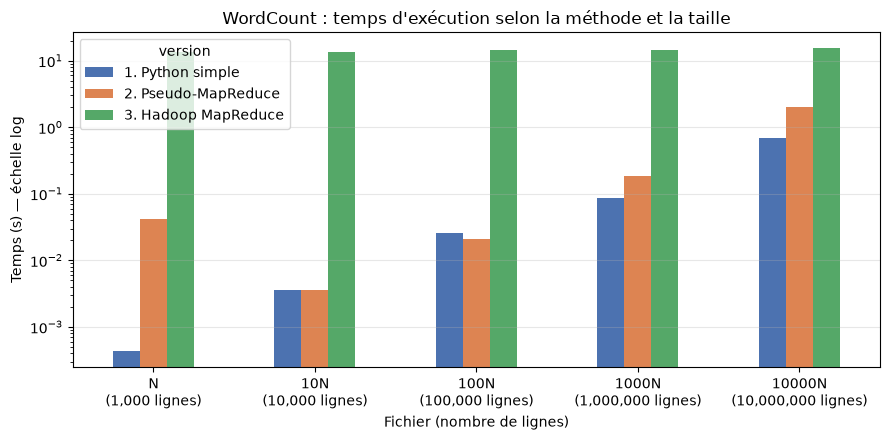

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(RESULTATS, columns=["version", "corpus", "temps_s"])
tab = df.pivot(index="corpus", columns="version", values="temps_s").loc[list(CORPUS)]
tab.insert(0, "lignes", [LIGNES[n] for n in tab.index])
display(tab.round(4))

ax = tab.drop(columns="lignes").plot.bar(figsize=(9, 4.5), rot=0, logy=True,
                                         color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("Temps (s) — échelle log")
ax.set_xlabel("Fichier (nombre de lignes)")
ax.set_xticklabels([f"{n}\n({LIGNES[n]:,d} lignes)" for n in tab.index])
ax.set_title("WordCount : temps d'exécution selon la méthode et la taille")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

Le temps pour Hadoop est quasiment constant (la majeure partie de ce temps est le lancement du job et pas du traitement de données) tandis que les versions Python et Pseudo-MapReduce augmentent significativement avec le volume.

In [39]:
# Décomposition du temps de la version 2 par phase
pd.DataFrame(PHASES_V2).set_index("corpus").round(4)

,map,shuffle,reduce,paires intermédiaires
corpus,,,,
N,0.0405,0.0015,0.0000,1000
10N,0.0031,0.0004,0.0000,10000
100N,0.0170,0.0037,0.0002,100000
1000N,0.1523,0.0305,0.0017,1000000
10000N,1.5594,0.4498,0.0184,10000000


### 4.2 Analyse

**Résultats** (mesurés sur le Mac, ils varient légèrement d'une exécution à l'autre)

| Fichier | Lignes | 1. Python simple | 2. Pseudo-MapReduce | 3. Hadoop MapReduce |
|---|---|---|---|---|
| `mots_N.txt` | 1 000 | 0,0002 s | 0,0004 s | 12,34 s |
| `mots_10N.txt` | 10 000 | 0,0011 s | 0,0113 s | 14,27 s |
| `mots_100N.txt` | 100 000 | 0,0092 s | 0,0206 s | 13,23 s |
| `mots_1000N.txt` | 1 000 000 | 0,0731 s | 0,1811 s | 13,29 s |
| `mots_10000N.txt` | 10 000 000 | 0,7225 s | 2,3881 s | 16,25 s |

Les trois méthodes donnent exactement les mêmes comptes (ex. `bouteille` : 12, 120, 1 200, 12 000, 120 000).

**Ce qu'on observe**
1. **Python simple est le plus rapide pour des petits fichiers.** Son temps est proportionnel à la taille du fichier : environ 10 fois plus de temps pour 10 fois plus de lignes, de 0,07 s sur 1000N à 0,72 s sur 10000N.
2. **Le pseudo-MapReduce est 2 à 3 fois plus lent** que Python simple. Il fait le même calcul, mais il garde en mémoire une paire `(mot, 1)` pour chaque mot, soit 10 millions de paires sur 10000N. Sur ce fichier, regrouper ces paires (`shuffle`) prend déjà un tiers du temps.
3. **Hadoop met environ 13 à 14 s jusqu'à 1 million de lignes**, quelle que soit la taille. Ce temps sert presque entièrement à démarrer : Java, YARN et HDFS.
4. **À 10 millions de lignes, Hadoop commence à ralentir** (16,3 s, soit environ 3 s de plus). C'est la première fois que le traitement des données pèse vraiment dans son temps total.
5. **L'écart se réduit quand le volume augmente.** Les versions 1 et 2 ralentissent avec la taille, alors que Hadoop reste presque stable. Sur 1 000 lignes, Hadoop est environ 60 000 fois plus lent que Python simple ; sur 10 millions de lignes, seulement environ 22 fois.
6. **Hadoop ne travaille toujours pas en parallèle.** Même à 61 Mo, le fichier tient dans un seul bloc HDFS (128 Mo), donc un seul mapper est lancé. Le Combiner résume quand même les 10 millions de paires en quelques totaux par mot avant de les envoyer au reducer.

Ces ordres de grandeur sont proches de ceux évoqués dans le pdf (0,012 s, 0,017 s et 12 s).

**Quand Hadoop devient-il utile ?**
Sur une seule machine et avec un seul mapper, Hadoop ne rattrapera pas Python simple : quand le fichier grossit, son temps augmente lui aussi. Il devient intéressant quand le fichier occupe **de nombreux blocs** traités **en parallèle sur plusieurs machines** (un cluster), et quand les données sont **trop grosses pour un seul ordinateur** (centaines de Go, To).

**Comparaison des trois méthodes**

| | 1. Python simple | 2. Pseudo-MapReduce | 3. Hadoop MapReduce |
|---|---|---|---|
| **Principe** | Une boucle + un dictionnaire | `mapper` → `shuffle` → `reducer` | Mêmes étapes, réparties sur des machines |
| **Outils** | Python | Python | Java, HDFS, YARN |
| **Temps sur 10000N** | 0,72 s | 2,39 s | 16,3 s |
| **Limite / atout** | Une seule machine | Une seule machine, beaucoup de mémoire | Lent à démarrer, mais passe à l'échelle et résiste aux pannes |
| **Usage** | Petits volumes | Comprendre MapReduce | Très gros volumes |

**Conclusion**
MapReduce ne rend pas un calcul plus rapide : il permet de le **répartir sur plusieurs machines**. Sur une seule machine et des fichiers de quelques dizaines de Mo, cette organisation coûte du temps. Elle devient indispensable quand les données sont trop volumineuses pour un seul ordinateur.

In [40]:
# Arrêt propre des services Hadoop (à exécuter à la fin)
for d in ["yarn --daemon stop nodemanager", "yarn --daemon stop resourcemanager",
          "hdfs --daemon stop datanode", "hdfs --daemon stop namenode"]:
    sh(d, check=False)
print(sh("jps").stdout)

52418 YarnChild
52248 RunJar
52666 Jps
52366 MRAppMaster

